# Práctica 4a. Detección de vehículos, personas y matrículas
Visión por Computador (ULPGC). Cuaderno para Google Colab (GPU T4: *Entorno de ejecución → Cambiar tipo de entorno*).

**Contenido**
1. Entorno y configuración
2. Datos: vídeo de test y dataset de matrículas (UC3M-LP)
3. Detector general preentrenado (personas y vehículos)
4. Detector de matrículas: entrenamiento y evaluación
5. Prueba sobre el vídeo de test
6. Pipeline completo: seguimiento, conteo, matrículas, vídeo de salida y CSV
- Apéndice A. Solo autor: generar `UC3M_RS.zip`

> La lectura del texto de la matrícula (OCR) se añade en la práctica 4b (`VC_P4b.ipynb`): el CSV de este cuaderno ya reserva la columna `texto_matricula`, que aquí queda vacía.

## 1. Entorno y configuración

In [1]:
!nvidia-smi
!pip install -q ultralytics lap

/bin/bash: line 1: nvidia-smi: command not found


In [2]:
import os, glob, csv, math, shutil, collections
import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

print("Torch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Torch: 2.14.1+cpu
GPU disponible: False


### 1.1 Rutas, enlaces y función de descarga
El dataset y el vídeo se bajan solos desde los enlaces de abajo (si no existen ya). Montar Drive es opcional y solo sirve para guardar los resultados.

In [3]:
# ---- ENLACES PÚBLICOS ----
DATASET_URL = "https://drive.google.com/file/d/1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A/view?usp=sharing"      # UC3M_RS.zip (imágenes reducidas + labels + ground_truth.csv + yaml)
VIDEO_URL   = "https://drive.google.com/file/d/1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8/view?usp=drive_link"   # vídeo de test de la práctica
WEIGHTS_URL = "https://drive.google.com/file/d/1aX8Jv_dvw7f0s84GrwtZNvCrDgQMhnSt/view?usp=drive_link"   # best.pt del detector de matrículas ya entrenado

# ---- Rutas locales de Colab ----
VIDEO   = "/content/CO142.MP4"
RS_DS   = "/content/UC3M_RS"          # dataset reducido a 1920 px
YAML    = "/content/uc3m_rs.yaml"
RUNS_DIR = "/content/runs"            # cambiar a una ruta de Drive si se quiere persistir

# ---- Solo para el autor: dataset original convertido en Drive ----
USAR_DRIVE = False
DRIVE_DS   = "/content/drive/MyDrive/VC_P4/UC3M_LP_YOLO"
LOCAL_DS   = "/content/UC3M_LP_YOLO"

if USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RUNS_DIR = "/content/drive/MyDrive/VC_P4/runs"

def descargar(url, destino):
    """Descarga con gdown si el archivo no existe."""
    if os.path.exists(destino):
        print("Ya existe:", destino); return
    if url.startswith("PEGA_AQUI") or not url:
        raise ValueError(f"Falta el enlace para {destino}. Edita la celda de configuración.")
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
    import gdown
    gdown.download(url, destino, quiet=False, fuzzy=True)

## 2. Datos

### 2.1 Vídeo de test
Se descarga automáticamente si no existe y se muestran sus características.

In [4]:
descargar(VIDEO_URL, VIDEO)
print("Vídeo existe:", os.path.exists(VIDEO))

Downloading...
From (original): https://drive.google.com/uc?id=1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8
From (redirected): https://drive.google.com/uc?id=1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8&confirm=t&uuid=a2b53a32-0785-4a25-b81e-37c31f0a99c7
To: /content/CO142.MP4
100%|██████████| 201M/201M [00:02<00:00, 75.5MB/s]

Vídeo existe: True


In [5]:
vid = cv2.VideoCapture(VIDEO)
w   = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH))
h   = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = vid.get(cv2.CAP_PROP_FPS)
n   = int(vid.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{w}x{h}, {fps:.1f} fps, {n} fotogramas")
vid.release()

1920x1080, 25.0 fps, 2832 fotogramas


### 2.2 Dataset UC3M-LP: obtención
Convertido a formato YOLO con `convert_uc3m_lp_to_yolo.py` (una clase: `license_plate`). Originales de 5184×3888, reducidos a 1920 px de ancho para entrenar (las labels son normalizadas y no cambian).

Descarga `UC3M_RS.zip` y lo descomprime. Contiene `train/ val/ test/` con `images/` y `labels/`, y `ground_truth.csv` (con la matrícula de referencia, para 4b). También genera el `.yaml` que usa YOLO.

In [6]:
if not os.path.exists(RS_DS):
    descargar(DATASET_URL, "/content/UC3M_RS.zip")
    !unzip -q /content/UC3M_RS.zip -d /content/
else:
    print("Ya existe", RS_DS)

with open(YAML, "w") as fy:
    fy.write(f"train: {RS_DS}/train/images\n")
    fy.write(f"val: {RS_DS}/val/images\n")
    fy.write(f"test: {RS_DS}/test/images\n")
    fy.write("nc: 1\n")
    fy.write("names: ['license_plate']\n")
print(open(YAML).read())

Downloading...
From (original): https://drive.google.com/uc?id=1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A
From (redirected): https://drive.google.com/uc?id=1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A&confirm=t&uuid=ebed2bd6-aa18-4914-acd7-53744ca13fcc
To: /content/UC3M_RS.zip
100%|██████████| 1.45G/1.45G [00:42<00:00, 34.5MB/s]


train: /content/UC3M_RS/train/images
val: /content/UC3M_RS/val/images
test: /content/UC3M_RS/test/images
nc: 1
names: ['license_plate']



### 2.3 Dataset UC3M-LP: verificación

In [7]:
for split in ["train", "val", "test"]:
    ims = glob.glob(f"{RS_DS}/{split}/images/*.jpg")
    lbs = glob.glob(f"{RS_DS}/{split}/labels/*.txt")
    vacias = sum(1 for f in lbs if os.path.getsize(f) == 0)
    n_cajas = sum(len(open(f).read().strip().splitlines()) for f in lbs)
    print(f"{split}: {len(ims)} imágenes, {len(lbs)} labels, {vacias} vacías, {n_cajas} matrículas")

if os.path.exists(f"{RS_DS}/ground_truth.csv"):
    with open(f"{RS_DS}/ground_truth.csv", newline="", encoding="utf-8") as f:
        filas = list(csv.DictReader(f))
    print("Filas ground truth:", len(filas))
    print("Longitudes de 'text':", collections.Counter(len(r["text"]) for r in filas))

train: 1264 imágenes, 1264 labels, 0 vacías, 1667 matrículas
val: 316 imágenes, 316 labels, 0 vacías, 389 matrículas
test: 395 imágenes, 395 labels, 0 vacías, 491 matrículas
Filas ground truth: 2547
Longitudes de 'text': Counter({7: 2525, 8: 22})


### 2.4 Dataset UC3M-LP: comprobación visual de una imagen con su label

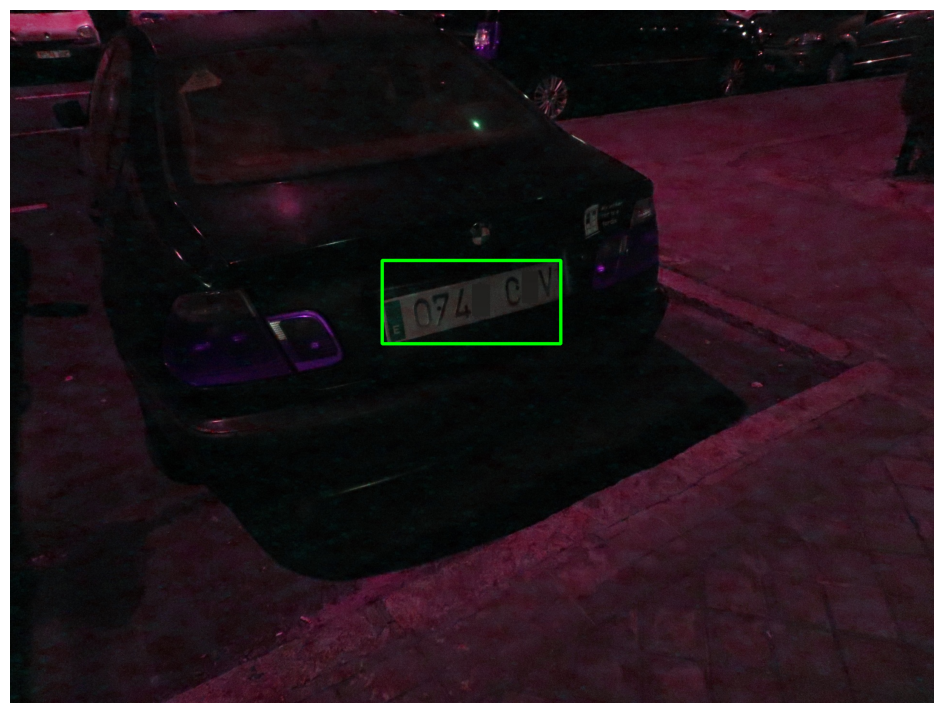

In [8]:
muestra = sorted(glob.glob(f"{RS_DS}/train/images/*.jpg"))[0]
img = cv2.imread(muestra)
H, W = img.shape[:2]
lab = muestra.replace("/images/", "/labels/").replace(".jpg", ".txt")

for linea in open(lab).read().strip().splitlines():
    _, xc, yc, bw, bh = map(float, linea.split())
    x1, y1 = int((xc - bw/2) * W), int((yc - bh/2) * H)
    x2, y2 = int((xc + bw/2) * W), int((yc + bh/2) * H)
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 5)

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.show()

## 3. Detector general preentrenado: personas y vehículos
Mismo esquema que los cuadernos de ejemplo (`box.xyxy`, `box.conf`, `box.cls`, `cv2.rectangle`, `cv2.putText`). Clases COCO de interés, con su etiqueta asociada al id.


0: 384x640 1 person, 1 car, 1 bus, 358.9ms
Speed: 23.3ms preprocess, 358.9ms inference, 26.4ms postprocess per image at shape (1, 3, 384, 640)
person 0.84
bus 0.82
car 0.68


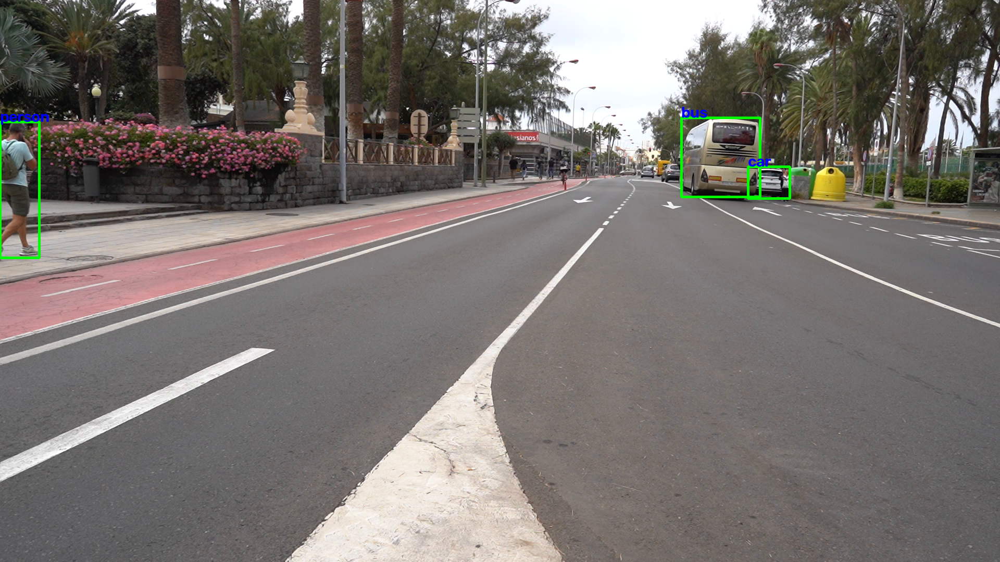

In [9]:
from google.colab.patches import cv2_imshow

model = YOLO('yolo11n.pt')

classNames = {0: "person", 1: "bicycle", 2: "car", 3: "motorbike", 5: "bus", 7: "truck"}
clases_interes = list(classNames.keys())

vid = cv2.VideoCapture(VIDEO)
vid.set(cv2.CAP_PROP_POS_FRAMES, 100)   # fotograma de prueba
ret, img = vid.read()
vid.release()

if ret:
    results = model(img, classes=clases_interes)
    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
            confidence = math.ceil(box.conf[0] * 100) / 100
            cls = int(box.cls[0])
            print(classNames[cls], confidence)

            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(img, classNames[cls], (x1, y1),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    cv2_imshow(img)

## 4. Detector de matrículas: entrenamiento y evaluación

### 4.1 Entrenamiento (opcional, ~1 h en T4)
Los resultados se guardan en `RUNS_DIR` (por defecto `/content/runs`; en Drive si `USAR_DRIVE = True`). Tras el entrenamiento, `runs/plate_yolo11n/` contiene `results.png` (pérdidas y métricas), curvas PR, matriz de confusión y `weights/best.pt`.

Si no se quiere entrenar, pasar a la sección 4.2 que descarga los pesos ya entrenados.

In [ ]:
model_pl = YOLO('yolo11n.pt')
res = model_pl.train(
    data=YAML,
    imgsz=1280,
    epochs=40,
    patience=10,
    batch=4,
    device=0,
    workers=2,
    project=RUNS_DIR,
    name="plate_yolo11n",
    exist_ok=True,
    conf=0.15
)

### 4.2 Pesos del detector
Si el detector se entrenó en esta sesión, se usan esos pesos; si no, se descargan de `WEIGHTS_URL`.

In [10]:
# Pesos del detector de matrículas. Si no se ha entrenado en esta sesión, se descargan de WEIGHTS_URL.
PESOS = f"{RUNS_DIR}/plate_yolo11n/weights/best.pt"
if not os.path.exists(PESOS):
    os.makedirs(os.path.dirname(PESOS), exist_ok=True)
    descargar(WEIGHTS_URL, PESOS)
print("Pesos:", PESOS, "| existe:", os.path.exists(PESOS))

Downloading...
From: https://drive.google.com/uc?id=1aX8Jv_dvw7f0s84GrwtZNvCrDgQMhnSt
To: /content/runs/plate_yolo11n/weights/best.pt
100%|██████████| 5.55M/5.55M [00:00<00:00, 38.4MB/s]

Pesos: /content/runs/plate_yolo11n/weights/best.pt | existe: True


### 4.3 Curvas de entrenamiento

In [11]:
from IPython.display import Image, display

resultados_png = f"{RUNS_DIR}/plate_yolo11n/results.png"
if os.path.exists(resultados_png):
    display(Image(resultados_png, width=900))
else:
    print("No hay curvas de entrenamiento: el detector no se entrenó en esta sesión (se usan los pesos descargados).")

No hay curvas de entrenamiento: el detector no se entrenó en esta sesión (se usan los pesos descargados).


### 4.4 Evaluación sobre el conjunto de test

In [13]:
best = YOLO(f"{RUNS_DIR}/plate_yolo11n/weights/best.pt")
metrics = best.val(data=YAML, split="test", imgsz=1280,
                   project="/content/runs/detect", name="test_eval", exist_ok=True)
print("mAP50:   ", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 981.8±778.8 MB/s, size: 805.5 KB)
val: Scanning /content/UC3M_RS/test/labels... 395 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 395/395 661.5it/s 0.6s
val: New cache created: /content/UC3M_RS/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 12.7s/it 5:16
                   all        395        491       0.99      0.994      0.994      0.908
Speed: 20.2ms preprocess, 738.0ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/test_eval
mAP50:    0.993536675683008
mAP50-95: 0.9078293518717363


### 4.5 Evaluación sobre validación (mismos ajustes que test)

In [15]:
# Evaluación en validación con exactamente los mismos ajustes que en test
metrics_val = best.val(data=YAML, split="val", imgsz=1280,
                       project="/content/runs/detect", name="val_eval", exist_ok=True)
print("mAP50:   ", metrics_val.box.map50)
print("mAP50-95:", metrics_val.box.map)

Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2346.8±1001.9 MB/s, size: 884.6 KB)
val: Scanning /content/UC3M_RS/val/labels... 316 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 316/316 684.4it/s 0.5s
val: New cache created: /content/UC3M_RS/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 12.4s/it 4:08
                   all        316        389      0.989      0.977      0.994      0.891
Speed: 24.7ms preprocess, 712.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val_eval
mAP50:    0.9937577591191946
mAP50-95: 0.8911454064531451


### 4.6 Guardar los resultados en Drive (opcional)

In [16]:
# Copia a Drive solo si Drive está montado
DEST = "/content/drive/MyDrive/VC_P4/runs"
if os.path.isdir("/content/drive/MyDrive"):
    !mkdir -p {DEST}
    if os.path.isdir("/content/runs/plate_yolo11n"):
        !cp -r /content/runs/plate_yolo11n {DEST}/
    if os.path.isdir("/content/runs/detect/test_eval"):
        !cp -r /content/runs/detect/test_eval {DEST}/
    if os.path.isdir("/content/runs/detect/val_eval"):
        !cp -r /content/runs/detect/val_eval {DEST}/
    !ls {DEST}
else:
    print("Drive no está montado: no se copia nada.")

Drive no está montado: no se copia nada.


## 5. Prueba sobre el vídeo de test

### 5.1 Detector de matrículas sobre un fotograma


0: 736x1280 2 license_plates, 2077.0ms
Speed: 79.1ms preprocess, 2077.0ms inference, 28.9ms postprocess per image at shape (1, 3, 736, 1280)
Matrículas detectadas: 2


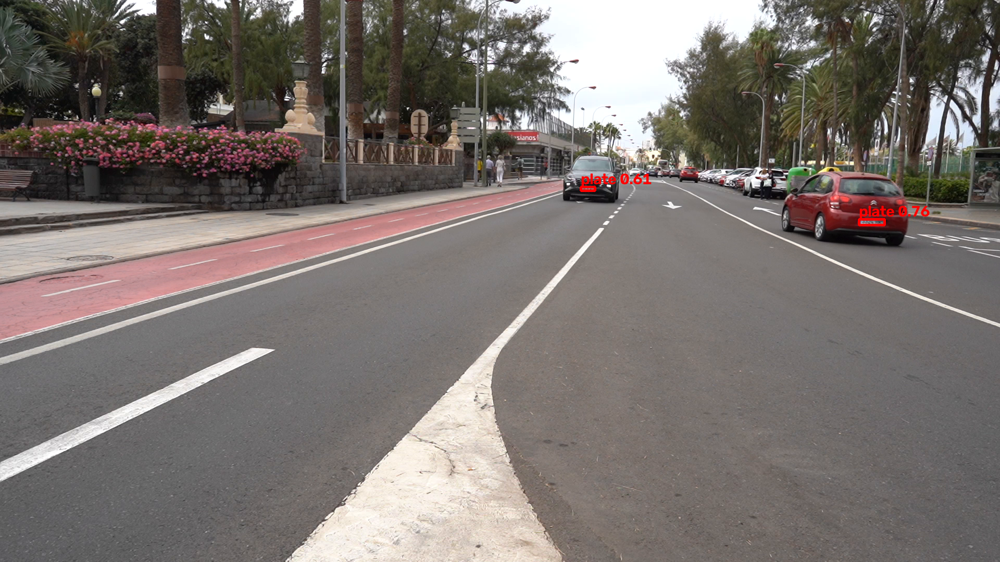

In [18]:
from google.colab.patches import cv2_imshow

plate_model = YOLO(PESOS)

vid = cv2.VideoCapture(VIDEO)
vid.set(cv2.CAP_PROP_POS_FRAMES, 1000)
ret, img = vid.read()
vid.release()

res = plate_model(img, conf=0.25)[0]
for box in res.boxes:
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
    conf = math.ceil(box.conf[0] * 100) / 100
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)
    cv2.putText(img, f"plate {conf}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
print("Matrículas detectadas:", len(res.boxes))
cv2_imshow(img)

### 5.2 Personas, vehículos (tracking) y matrículas: tramo de vídeo anotado
Prueba visual sobre un tramo corto. Requiere haber ejecutado antes la celda 5.1 (define `plate_model`).

In [22]:
# Vídeo anotado: personas y vehículos (tracking) + matrículas, reproducido en el cuaderno
import subprocess, base64
from IPython.display import HTML, display

INICIO = 900      # fotograma de inicio
SEGUNDOS = 30     # duración del tramo
ANCHO_OUT = 960   # reducimos para que el vídeo pese menos

# Modelo de personas/vehículos, creado aquí para que el tracker empiece limpio en cada ejecución
track_model = YOLO('yolo11n.pt')
classNames = {0: "person", 1: "bicycle", 2: "car", 3: "motorbike", 5: "bus", 7: "truck"}
clases_interes = list(classNames.keys())

vid = cv2.VideoCapture(VIDEO)
fps = vid.get(cv2.CAP_PROP_FPS)
w = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH)); h = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
sw, sh = ANCHO_OUT, int(h * ANCHO_OUT / w)
vid.set(cv2.CAP_PROP_POS_FRAMES, INICIO)

out = cv2.VideoWriter("/content/tmp_out.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (sw, sh))
for _ in range(int(fps * SEGUNDOS)):
    ret, img = vid.read()
    if not ret:
        break

    # Seguimiento de personas y vehículos (cajas verdes con ID)
    res_obj = track_model.track(img, persist=True, classes=clases_interes, verbose=False)[0]
    for box in res_obj.boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        nombre = classNames[int(box.cls[0])]
        track_id = str(int(box.id[0])) if box.id is not None else ""
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{track_id} {nombre}", (x1, y1 - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

    # Matrículas (cajas rojas)
    res = plate_model(img, conf=0.25, verbose=False)[0]
    for box in res.boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        conf = math.ceil(box.conf[0] * 100) / 100
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)
        cv2.putText(img, f"plate {conf}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    out.write(cv2.resize(img, (sw, sh)))
vid.release(); out.release()

# mp4v no se reproduce en el navegador: convertimos a H.264
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "/content/tmp_out.mp4",
                "-vcodec", "libx264", "-pix_fmt", "yuv420p", "/content/tmp_h264.mp4"], check=True)

data = base64.b64encode(open("/content/tmp_h264.mp4", "rb").read()).decode()
display(HTML(f'<video width="{sw}" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

## 6. Pipeline completo: seguimiento, conteo, matrículas, vídeo de salida y CSV
Procesa el vídeo entero en dos pasadas:
1. **Detección y seguimiento** de personas y vehículos (YOLO11n + BoT-SORT) y **detección de la matrícula dentro del recorte de cada vehículo** con el detector entrenado en la sección 4.
2. **Salida:** vídeo anotado a resolución original y CSV con los campos del enunciado. Se hace en una segunda pasada porque la clase definitiva de cada ID es la más frecuente a lo largo del vídeo, y el conteo solo incluye IDs presentes en al menos `MIN_FRAMES` fotogramas (evita contar detecciones espurias). La columna `texto_matricula` queda vacía; la rellena la práctica 4b.

### 6.1 Pasada 1: detección, seguimiento y matrículas

In [24]:
# ---- Configuración del pipeline ----
MAX_FRAMES  = None
VEHICULOS   = {2, 3, 5, 7}      # car, motorbike, bus, truck
CONF_PLACA  = 0.25
MIN_FRAMES  = 25        # un ID cuenta en el conteo si aparece al menos en tantos fotogramas
VIDEO_OUT = "/content/salida_p4a.mp4"
CSV_OUT   = "/content/resultado_p4a.csv"
CSV_VEH   = "/content/resumen_vehiculos_p4a.csv"

classNames = {0: "person", 1: "bicycle", 2: "car", 3: "motorbike", 5: "bus", 7: "truck"}
clases_interes = list(classNames.keys())

track_model = YOLO('yolo11n.pt')      # modelo nuevo para que el tracker empiece limpio
plate_model = YOLO(PESOS)

vid = cv2.VideoCapture(VIDEO)
fps = vid.get(cv2.CAP_PROP_FPS)
W = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))

# ---- Pasada 1: detección, seguimiento y matrículas ----
registros = collections.defaultdict(list)     # fotograma -> lista de detecciones
fotograma = 0
while True:
    ret, img = vid.read()
    if not ret or (MAX_FRAMES is not None and fotograma >= MAX_FRAMES):
        break

    res = track_model.track(img, persist=True, classes=clases_interes, verbose=False)[0]
    for box in res.boxes:
        if box.id is None:
            continue
        cls = int(box.cls[0]); tid = int(box.id[0])
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        reg = dict(tid=tid, cls=classNames[cls], conf=round(float(box.conf[0]), 2),
                   caja=(x1, y1, x2, y2), placa=None)

        # Matrícula buscada dentro del recorte del vehículo (así ocupa un tamaño parecido al del entrenamiento)
        if cls in VEHICULOS and (x2 - x1) > 40 and (y2 - y1) > 40:
            rp = plate_model(img[y1:y2, x1:x2], imgsz=640, conf=CONF_PLACA, verbose=False)[0]
            if len(rp.boxes):
                b = rp.boxes[int(rp.boxes.conf.argmax())]
                px1, py1, px2, py2 = [int(v) for v in b.xyxy[0]]
                reg["placa"] = (round(float(b.conf[0]), 2), x1 + px1, y1 + py1, x1 + px2, y1 + py2)
        registros[fotograma].append(reg)
    fotograma += 1
vid.release()
n_proc = fotograma
print("Pasada 1 terminada:", n_proc, "fotogramas")

Pasada 1 terminada: 2832 fotogramas


### 6.2 Pasada 2: conteo, vídeo de salida y CSV

In [25]:
# ---- Clase definitiva de cada ID (la más frecuente) y conteo ----
votos = collections.defaultdict(collections.Counter)
for regs in registros.values():
    for r in regs:
        votos[r["tid"]][r["cls"]] += 1
clase_final = {tid: v.most_common(1)[0][0] for tid, v in votos.items()}
n_frames    = {tid: sum(v.values()) for tid, v in votos.items()}
estables    = {tid for tid, n in n_frames.items() if n >= MIN_FRAMES}

primer_frame, ultimo_frame, con_placa, primer_placa = {}, {}, set(), {}
for fr in sorted(registros):
    for r in registros[fr]:
        primer_frame.setdefault(r["tid"], fr)
        ultimo_frame[r["tid"]] = fr
        if r["placa"]:
            con_placa.add(r["tid"])
            primer_placa.setdefault(r["tid"], fr)

# ---- Pasada 2: vídeo de salida (resolución original) y CSV ----
vid = cv2.VideoCapture(VIDEO)
writer = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
filas = []
for fr in range(n_proc):
    ret, img = vid.read()
    if not ret:
        break
    for r in registros.get(fr, []):
        tid = r["tid"]; nombre = clase_final[tid]
        x1, y1, x2, y2 = r["caja"]; placa = r["placa"]

        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{tid} {nombre}", (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        if placa:
            cv2.rectangle(img, (placa[1], placa[2]), (placa[3], placa[4]), (0, 0, 255), 3)
            cv2.putText(img, f"plate {placa[0]}", (placa[1], max(20, placa[2] - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)

        # texto_matricula queda vacío: lo rellena la práctica 4b (OCR)
        filas.append([fr, nombre, r["conf"], tid, x1, y1, x2, y2,
                      "si" if placa else "no",
                      placa[0] if placa else "", *(placa[1:] if placa else ["", "", "", ""]), ""])

    # Contador: IDs estables ya vistos, por clase mayoritaria
    cuenta = collections.Counter(clase_final[t] for t in estables if primer_frame[t] <= fr)
    n_placas = sum(1 for t, f0 in primer_placa.items() if t in estables and f0 <= fr)
    cuenta["plate"] = n_placas
    y = 40
    for nombre, n in cuenta.items():
        cv2.putText(img, f"{nombre}: {n}", (20, y), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2); y += 35
    writer.write(img)
vid.release(); writer.release()

cabecera = ["fotograma", "tipo_objeto", "confianza", "identificador_tracking", "x1", "y1", "x2", "y2",
            "matricula", "confianza_matricula", "mx1", "my1", "mx2", "my2", "texto_matricula"]
with open(CSV_OUT, "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f); wr.writerow(cabecera); wr.writerows(filas)
with open(CSV_VEH, "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["identificador_tracking", "tipo_objeto", "primer_fotograma", "ultimo_fotograma",
                 "n_fotogramas", "estable", "matricula_detectada"])
    for tid in sorted(n_frames):
        wr.writerow([tid, clase_final[tid], primer_frame[tid], ultimo_frame[tid], n_frames[tid],
                     "si" if tid in estables else "no", "si" if tid in con_placa else "no"])

# ---- Resumen ----
print(f"Fotogramas procesados: {n_proc} | filas en el CSV: {len(filas)}")
print("IDs totales por clase:   ", dict(collections.Counter(clase_final.values())))
print(f"IDs estables (>= {MIN_FRAMES} fotogramas):", dict(collections.Counter(clase_final[t] for t in estables)))
veh_estables = [t for t in estables if clase_final[t] in {classNames[c] for c in VEHICULOS}]
print(f"Vehículos estables con matrícula detectada: {sum(t in con_placa for t in veh_estables)} de {len(veh_estables)}")
n_placas_total = sum(1 for t in con_placa if t in estables)
print(f"Matrículas detectadas (una por vehículo estable): {n_placas_total}")

Fotogramas procesados: 2832 | filas en el CSV: 9725
IDs totales por clase:    {'bus': 1, 'car': 40, 'person': 16, 'bicycle': 1, 'motorbike': 1}
IDs estables (>= 25 fotogramas): {'bus': 1, 'car': 38, 'person': 13}
Vehículos estables con matrícula detectada: 31 de 39
Matrículas detectadas (una por vehículo estable): 31


### 6.3 Ver y descargar el resultado

In [27]:
import subprocess, base64
from IPython.display import HTML, display
from google.colab import files

subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO_OUT, "-vcodec", "libx264",
                "-pix_fmt", "yuv420p", "/content/salida_p4a_h264.mp4"], check=True)
mb = os.path.getsize("/content/salida_p4a_h264.mp4") / 1e6
print(f"Vídeo: {mb:.1f} MB")
if mb < 25:
    data = base64.b64encode(open("/content/salida_p4a_h264.mp4", "rb").read()).decode()
    display(HTML(f'<video width="960" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))
else:
    files.download("/content/salida_p4a_h264.mp4")
files.download(CSV_OUT); files.download(CSV_VEH)

Vídeo: 55.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Apéndice A. Solo autor: generar `UC3M_RS` desde el original
No hace falta para ejecutar el cuaderno. Requiere `USAR_DRIVE = True` (en la configuración, antes de ejecutar nada) y el dataset convertido en Drive.
Crea la versión reducida, copia `ground_truth.csv` y genera `UC3M_RS.zip` para subirlo y enlazarlo en `DATASET_URL`.

In [ ]:
if USAR_DRIVE and not os.path.exists(RS_DS):
    if not os.path.exists(LOCAL_DS):
        !cp -r "{DRIVE_DS}" /content/
    ANCHO = 1920
    for split in ["train", "val", "test"]:
        os.makedirs(f"{RS_DS}/{split}/images", exist_ok=True)
        os.makedirs(f"{RS_DS}/{split}/labels", exist_ok=True)
        for f in glob.glob(f"{LOCAL_DS}/{split}/images/*.jpg"):
            img = cv2.imread(f)
            H, W = img.shape[:2]
            nuevo = cv2.resize(img, (ANCHO, int(H * ANCHO / W)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(f"{RS_DS}/{split}/images/{os.path.basename(f)}", nuevo)
        for f in glob.glob(f"{LOCAL_DS}/{split}/labels/*.txt"):
            shutil.copy(f, f"{RS_DS}/{split}/labels/")
        print(split, "listo")
    # ground truth con coordenadas en píxeles originales (img_w, img_h incluidos)
    shutil.copy(f"{LOCAL_DS}/ground_truth.csv", RS_DS)
    !cd /content && zip -qr UC3M_RS.zip UC3M_RS
    !cp /content/UC3M_RS.zip /content/drive/MyDrive/VC_P4/
    !ls -lh /content/drive/MyDrive/VC_P4/UC3M_RS.zip